In [11]:
import pandas as pd
import sklearn
df = pd.read_csv("../data/processed_traffic.csv")

print(df.shape)
print(df.head())
print(df.columns)

(840, 8)
   reading_id road_id sensor_id            timestamp  vehicle_count  \
0           1    R001      S001  2026-08-20 00:00:00             11   
1           2    R002      S002  2026-08-20 00:00:00             21   
2           3    R003      S003  2026-08-20 00:00:00             42   
3           4    R004      S004  2026-08-20 00:00:00             50   
4           5    R005      S005  2026-08-20 00:00:00             14   

   avg_speed  density congestion  
0      20.22    77.28       High  
1      54.22     7.07        Low  
2      29.74    69.90       High  
3      23.77    68.77       High  
4      33.00    84.14       High  
Index(['reading_id', 'road_id', 'sensor_id', 'timestamp', 'vehicle_count',
       'avg_speed', 'density', 'congestion'],
      dtype='object')


In [2]:
print(df.dtypes)
print(df.isnull().sum())

reading_id         int64
road_id           object
sensor_id         object
timestamp         object
vehicle_count      int64
avg_speed        float64
density          float64
congestion        object
dtype: object
reading_id       0
road_id          0
sensor_id        0
timestamp        0
vehicle_count    0
avg_speed        0
density          0
congestion       0
dtype: int64


In [3]:
df["timestamp"] = pd.to_datetime(df["timestamp"])

df["hour"] = df["timestamp"].dt.hour
df["day_of_week"] = df["timestamp"].dt.dayofweek

In [4]:
df["is_peak_hour"] = df["hour"].apply(
    lambda x: 1 if (7 <= x <= 10 or 17 <= x <= 20) else 0
)

In [5]:
df["road_id_encoded"] = df["road_id"].astype("category").cat.codes

In [6]:
features = [
    "road_id_encoded",
    "vehicle_count",
    "avg_speed",
    "density",
    "hour",
    "day_of_week",
    "is_peak_hour"
]

X = df[features]
y = df["congestion"]

print(X.head())
print(y.head())

   road_id_encoded  vehicle_count  avg_speed  density  hour  day_of_week  \
0                0             11      20.22    77.28     0            3   
1                1             21      54.22     7.07     0            3   
2                2             42      29.74    69.90     0            3   
3                3             50      23.77    68.77     0            3   
4                4             14      33.00    84.14     0            3   

   is_peak_hour  
0             0  
1             0  
2             0  
3             0  
4             0  
0    High
1     Low
2    High
3    High
4    High
Name: congestion, dtype: object


In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(672, 7)
(168, 7)


In [13]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

model.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=5, random_state=42)

In [14]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Baseline Accuracy:", accuracy)
print(classification_report(y_test, y_pred))

Baseline Accuracy: 1.0
              precision    recall  f1-score   support

        High       1.00      1.00      1.00        81
         Low       1.00      1.00      1.00        24
      Medium       1.00      1.00      1.00        63

    accuracy                           1.00       168
   macro avg       1.00      1.00      1.00       168
weighted avg       1.00      1.00      1.00       168



In [15]:
import os
import joblib

os.makedirs("../models", exist_ok=True)

joblib.dump(model, "../models/congestion_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [16]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred)
print(cm)

Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

        High       1.00      1.00      1.00        81
         Low       1.00      1.00      1.00        24
      Medium       1.00      1.00      1.00        63

    accuracy                           1.00       168
   macro avg       1.00      1.00      1.00       168
weighted avg       1.00      1.00      1.00       168


Confusion Matrix:
[[81  0  0]
 [ 0 24  0]
 [ 0  0 63]]


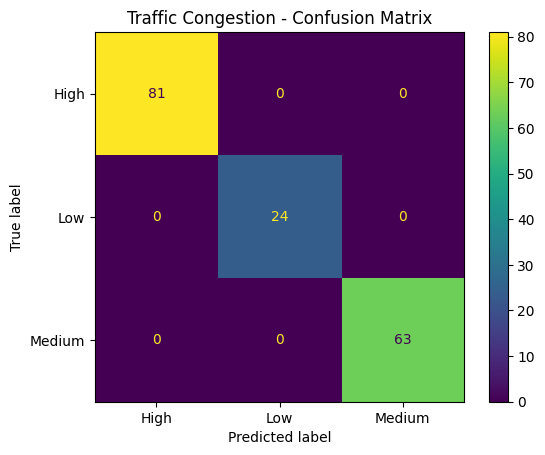

In [17]:
import matplotlib.pyplot as plt

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

disp.plot()
plt.title("Traffic Congestion - Confusion Matrix")
plt.show()

In [18]:
importance = pd.DataFrame({
    "feature": X.columns,
    "importance": model.feature_importances_
})

importance = importance.sort_values(
    "importance",
    ascending=False
)

print(importance)

           feature  importance
3          density         1.0
0  road_id_encoded         0.0
1    vehicle_count         0.0
2        avg_speed         0.0
4             hour         0.0
5      day_of_week         0.0
6     is_peak_hour         0.0


In [19]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

for depth in [3, 5, 7, 10]:
    test_model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    test_model.fit(X_train, y_train)

    pred = test_model.predict(X_test)

    print(
        "Max Depth:", depth,
        "| Accuracy:", accuracy_score(y_test, pred)
    )

Max Depth: 3 | Accuracy: 1.0
Max Depth: 5 | Accuracy: 1.0
Max Depth: 7 | Accuracy: 1.0
Max Depth: 10 | Accuracy: 1.0


In [20]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    model,
    X,
    y,
    cv=5,
    scoring="accuracy"
)

print("5-Fold CV Scores:", cv_scores)
print("Mean CV Accuracy:", cv_scores.mean())
print("Std CV Accuracy:", cv_scores.std())

5-Fold CV Scores: [1.         1.         1.         0.99404762 1.        ]
Mean CV Accuracy: 0.9988095238095237
Std CV Accuracy: 0.002380952380952372


In [21]:
import joblib

joblib.dump(model, "../models/congestion_model.pkl")

print("Final evaluated model saved as model-v1")

Final evaluated model saved as model-v1
